# Notebook 11 – Handling Imbalanced Data

## 1. What is Class Imbalance?
Class imbalance means one target class has many more records than another.

## 2. Balanced vs Imbalanced Dataset
- **Balanced:** classes have similar counts.
- **Imbalanced:** one class dominates the dataset.

## 3. Why Is It a Problem?
A model may mostly predict the majority class and still show high accuracy while failing to detect the minority class.

## 4. Inspect Class Balance
Example: 90 customers stayed and 10 customers churned.

Churn
No     90
Yes    10
Name: count, dtype: int64
Churn
No     90.0
Yes    10.0
Name: proportion, dtype: float64


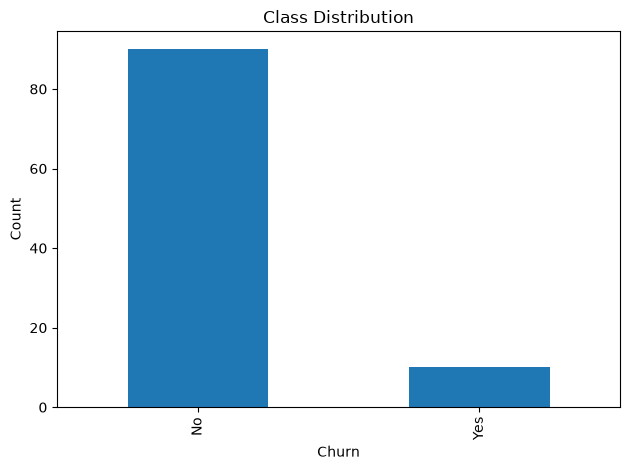

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

y = pd.Series(["No"] * 90 + ["Yes"] * 10, name="Churn")
print(y.value_counts())
print((y.value_counts(normalize=True) * 100).round(1))
y.value_counts().plot(kind="bar", title="Class Distribution")
plt.xlabel("Churn")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

### Output Explanation
The data contains 90 `No` records and 10 `Yes` records, so the target is imbalanced.

## 5. Why Accuracy Alone Can Mislead
Accuracy measures the fraction of all predictions that are correct. Predicting only the majority class here gives 90% accuracy but detects no churn cases. Also check precision, recall, F1-score, the confusion matrix, and often PR-AUC.

In [2]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_true = ["No"] * 90 + ["Yes"] * 10
y_pred = ["No"] * 100
print("Accuracy:", accuracy_score(y_true, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_true, y_pred, labels=["No", "Yes"]))
print(classification_report(y_true, y_pred, labels=["No", "Yes"], zero_division=0))

Accuracy: 0.9
Confusion matrix:
 [[90  0]
 [10  0]]
              precision    recall  f1-score   support

          No       0.90      1.00      0.95        90
         Yes       0.00      0.00      0.00        10

    accuracy                           0.90       100
   macro avg       0.45      0.50      0.47       100
weighted avg       0.81      0.90      0.85       100



### Output Explanation
Accuracy is 90%, but recall for `Yes` is 0: every minority-class example was missed.

## 6. Undersampling
Undersampling reduces majority-class records. **Random undersampling** removes majority examples at random. It can speed up training, but may discard useful information.

In [3]:
# Install imbalanced-learn if needed: %pip install imbalanced-learn
from imblearn.under_sampling import RandomUnderSampler
from collections import Counter

X = pd.DataFrame({"feature": range(100)})
y = pd.Series([0] * 90 + [1] * 10)
X_res, y_res = RandomUnderSampler(random_state=42).fit_resample(X, y)
print("Before:", Counter(y))
print("After:", Counter(y_res))

Before: Counter({0: 90, 1: 10})
After: Counter({0: 10, 1: 10})


## 7. Oversampling
- **Random oversampling:** duplicates minority-class examples; simple, but may overfit.
- **SMOTE:** creates synthetic minority examples using nearest neighbours.
- **Borderline-SMOTE:** focuses on minority examples near class boundaries; may amplify noise or overlap.

In [4]:
from imblearn.over_sampling import RandomOverSampler, SMOTE, BorderlineSMOTE
from collections import Counter

X = pd.DataFrame({"feature1": range(100), "feature2": [i % 7 for i in range(100)]})
y = pd.Series([0] * 90 + [1] * 10)

samplers = [
    RandomOverSampler(random_state=42),
    SMOTE(random_state=42, k_neighbors=3),
    BorderlineSMOTE(random_state=42, k_neighbors=3)
]
for sampler in samplers:
    X_res, y_res = sampler.fit_resample(X, y)
    print(type(sampler).__name__, Counter(y_res))

RandomOverSampler Counter({0: 90, 1: 90})
SMOTE Counter({0: 90, 1: 90})
BorderlineSMOTE Counter({0: 90, 1: 90})


## 8. Class Weights
Class weights make errors on the minority class more costly during training. Many estimators support `class_weight="balanced"`; it avoids creating synthetic rows.

## 9. When to Use Each Technique

| Technique | When it may help | Caution |
|---|---|---|
| Random undersampling | Very large majority class | May lose information |
| Random oversampling | Simple baseline, small minority class | Duplicates can overfit |
| SMOTE | Numeric features with enough minority neighbours | Synthetic examples may be unrealistic |
| Borderline-SMOTE | Minority class near decision boundary | Sensitive to noise/overlap |
| Class weights | Want to penalize minority errors without resampling | Not supported by every model |

## 10. Correct Workflow
Split the data first. Resample **only the training set**. Never resample the full dataset before splitting because this can contaminate test evaluation.

In [5]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

X = pd.DataFrame({"feature1": range(100), "feature2": [i % 7 for i in range(100)]})
y = pd.Series([0] * 90 + [1] * 10)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train_res, y_train_res = SMOTE(random_state=42, k_neighbors=3).fit_resample(X_train, y_train)
print("Training before:", y_train.value_counts().to_dict())
print("Training after:", y_train_res.value_counts().to_dict())
print("Test remains unchanged:", y_test.value_counts().to_dict())

Training before: {0: 72, 1: 8}
Training after: {0: 72, 1: 72}
Test remains unchanged: {0: 18, 1: 2}


### Final Takeaway
Choose the method based on data and error costs. Evaluate with recall, precision, F1-score, confusion matrix, and suitable curves—not accuracy alone.